In [1]:
import numpy as np
import pandas as pd
from itertools import product

In [2]:
pares = list(product(range(1, 7), repeat=2))

print(pares)
print("Cantidad de resultados:", len(pares))

[(1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (3, 1), (3, 2), (3, 3), (3, 4), (3, 5), (3, 6), (4, 1), (4, 2), (4, 3), (4, 4), (4, 5), (4, 6), (5, 1), (5, 2), (5, 3), (5, 4), (5, 5), (5, 6), (6, 1), (6, 2), (6, 3), (6, 4), (6, 5), (6, 6)]
Cantidad de resultados: 36


In [3]:
favorables = [par for par in pares if 6 in par]

print("Casos favorables:", len(favorables))
print("Casos:", favorables)

Casos favorables: 11
Casos: [(1, 6), (2, 6), (3, 6), (4, 6), (5, 6), (6, 1), (6, 2), (6, 3), (6, 4), (6, 5), (6, 6)]


In [4]:
total = len(pares)
cantidad_favorables = len(favorables)

prob_exacta = cantidad_favorables / total

print("Total de casos:", total)
print("Casos favorables:", cantidad_favorables)
print("Probabilidad exacta:", prob_exacta)
print("Porcentaje:", prob_exacta * 100, "%")

Total de casos: 36
Casos favorables: 11
Probabilidad exacta: 0.3055555555555556
Porcentaje: 30.555555555555557 %


In [5]:
rng = np.random.default_rng(42)

In [6]:
def simular_dados(N):
    tiradas = rng.integers(1, 7, size=(N, 2))
    tiene_seis = np.any(tiradas == 6, axis=1)
    probabilidad = np.mean(tiene_seis)
    
    return probabilidad

In [7]:
Ns = [100, 1000, 100000]

resultados = []

for N in Ns:
    estimacion = simular_dados(N)
    error = abs(estimacion - prob_exacta)
    
    resultados.append({
        "N": N,
        "Estimación": estimacion,
        "Valor exacto": prob_exacta,
        "Error": error
    })

tabla = pd.DataFrame(resultados)

tabla

,N,Estimación,Valor exacto,Error
0,100,0.24000,0.305556,0.065556
1,1000,0.31000,0.305556,0.004444
2,100000,0.30583,0.305556,0.000274


La probabilidad exacta de obtener al menos un 6 al lanzar dos dados es 11/36, aproximadamente 0.3056 o 30.56%.

Al aumentar el número de simulaciones, la estimación tiende a acercarse al valor exacto. La simulación con N = 100000 presenta normalmente un error menor.

Con pocas tiradas existe una mayor variación debido al azar, por lo que la estimación puede alejarse más de la probabilidad real.

ejercisio 2

In [8]:
from sklearn.datasets import load_iris

iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["species"] = iris.target_names[iris.target]

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [9]:
df["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [10]:
caracteristicas = iris.feature_names

estadisticos = df.groupby("species")[caracteristicas].agg(
    ["mean", "median", "std", "min", "max"]
)

estadisticos

sepal length (cm)                            sepal width (cm)  \
                        mean median       std  min  max             mean   
species                                                                    
setosa                 5.006    5.0  0.352490  4.3  5.8            3.428   
versicolor             5.936    5.9  0.516171  4.9  7.0            2.770   
virginica              6.588    6.5  0.635880  4.9  7.9            2.974   

                                      petal length (cm)                        \
           median       std  min  max              mean median       std  min   
species                                                                         
setosa        3.4  0.379064  2.3  4.4             1.462   1.50  0.173664  1.0   
versicolor    2.8  0.313798  2.0  3.4             4.260   4.35  0.469911  3.0   
virginica     3.0  0.322497  2.2  3.8             5.552   5.55  0.551895  4.5   

                petal width (cm)                             
            max             mean median       std  min  max  
species                                                      
setosa      1.9            0.246    0.2  0.105386  0.1  0.6  
versicolor  5.1            1.326    1.3  0.197753  1.0  1.8  
virginica   6.9            2.026    2.0  0.274650  1.4  2.5

In [11]:
cuartiles = df.groupby("species")[caracteristicas].quantile(
    [0.25, 0.50, 0.75]
)

cuartiles

sepal length (cm)  sepal width (cm)  petal length (cm)  \
species                                                                   
setosa     0.25              4.800             3.200              1.400   
           0.50              5.000             3.400              1.500   
           0.75              5.200             3.675              1.575   
versicolor 0.25              5.600             2.525              4.000   
           0.50              5.900             2.800              4.350   
           0.75              6.300             3.000              4.600   
virginica  0.25              6.225             2.800              5.100   
           0.50              6.500             3.000              5.550   
           0.75              6.900             3.175              5.875   

                 petal width (cm)  
species                            
setosa     0.25               0.2  
           0.50               0.2  
           0.75               0.3  
versicolor 0.25               1.2  
           0.50               1.3  
           0.75               1.5  
virginica  0.25               1.8  
           0.50               2.0  
           0.75               2.3

In [12]:
df_nan = df.copy()

rng_nan = np.random.default_rng(42)

for columna in caracteristicas:
    indices = rng_nan.choice(df_nan.index, size=3, replace=False)
    df_nan.loc[indices, columna] = np.nan

df_nan.isna().sum()

sepal length (cm)    3
sepal width (cm)     3
petal length (cm)    3
petal width (cm)     3
species              0
dtype: int64

In [13]:
for columna in caracteristicas:
    df_nan[columna] = df_nan.groupby("species")[columna].transform(
        lambda x: x.fillna(x.median())
    )

In [14]:
df_nan.isna().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Se utiliza la mediana para imputar los valores faltantes porque es menos sensible a valores extremos que la media. Además, al calcularla por especie se mantiene mejor la distribución característica de cada grupo.

Una característica que presenta medias bastante diferentes entre las tres especies puede separar mejor las especies, porque los valores de esa característica tienden a ser distintos según la especie. En cambio, una característica con medias parecidas tiene mayor dificultad para distinguirlas.

ejercisio 3 

In [15]:
def distancia_euclidiana(a, b):
    return np.sqrt(np.sum((a - b) ** 2))


def producto_punto(a, b):
    return np.sum(a * b)


def similitud_coseno(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

In [16]:
X = iris.data
y = iris.target

In [17]:
indices = [0, 1, 50, 100]

print("Índices utilizados:", indices)

for i in indices:
    print(i, iris.target_names[y[i]], X[i])

Índices utilizados: [0, 1, 50, 100]
0 setosa [5.1 3.5 1.4 0.2]
1 setosa [4.9 3.  1.4 0.2]
50 versicolor [7.  3.2 4.7 1.4]
100 virginica [6.3 3.3 6.  2.5]


In [18]:
pares_flores = [
    (0, 1),
    (0, 50),
    (0, 100)
]

resultados_flores = []

for i, j in pares_flores:
    a = X[i]
    b = X[j]
    
    resultados_flores.append({
        "Par": f"{i}-{j}",
        "Especies": f"{iris.target_names[y[i]]} - {iris.target_names[y[j]]}",
        "Distancia euclidiana": distancia_euclidiana(a, b),
        "Producto punto": producto_punto(a, b),
        "Similitud coseno": similitud_coseno(a, b)
    })

tabla_flores = pd.DataFrame(resultados_flores)

tabla_flores

,Par,Especies,Distancia euclidiana,Producto punto,Similitud coseno
0,0-1,setosa - setosa,0.538516,37.49,0.998579
1,0-50,setosa - versicolor,4.003748,53.76,0.928380
2,0-100,setosa - virginica,5.284884,52.58,0.860081


Para la distancia euclidiana, una distancia menor indica que las flores son más parecidas. Para la similitud coseno, un valor más cercano a 1 indica mayor similitud.

La comparación entre las flores permite observar que las flores de la misma especie tienden a presentar una menor distancia y una mayor similitud coseno que flores pertenecientes a especies diferentes.

La distancia euclidiana y la similitud coseno no necesariamente ordenan las flores exactamente igual, porque miden aspectos diferentes de los vectores: la distancia considera la separación entre los valores, mientras que el coseno considera principalmente la dirección de los vectores.

ejercisio 4

In [19]:
def descenso_gradiente(tasa, pasos=50):
    x = 10
    trayectoria = [x]
    
    for i in range(pasos):
        derivada = 2 * (x - 4)
        x = x - tasa * derivada
        trayectoria.append(x)
    
    return trayectoria

In [20]:
tasas = [0.01, 0.1, 1.1]

trayectorias = {}

for tasa in tasas:
    trayectorias[tasa] = descenso_gradiente(tasa, 50)
    
    print("Tasa:", tasa)
    print("x final:", trayectorias[tasa][-1])
    print()

Tasa: 0.01
x final: 6.1850180805227035

Tasa: 0.1
x final: 4.000085634861563

Tasa: 1.1
x final: 54606.6289000133



Matplotlib is building the font cache; this may take a moment.


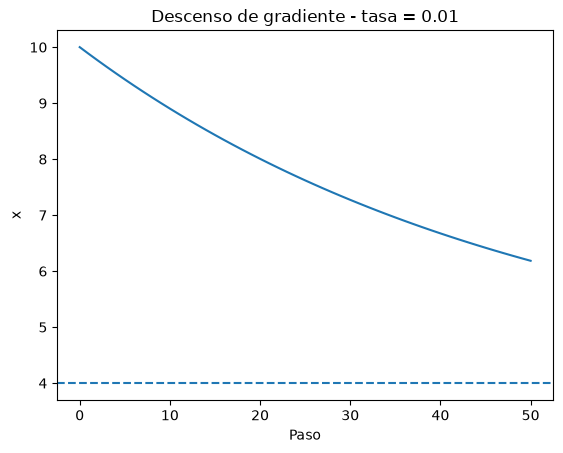

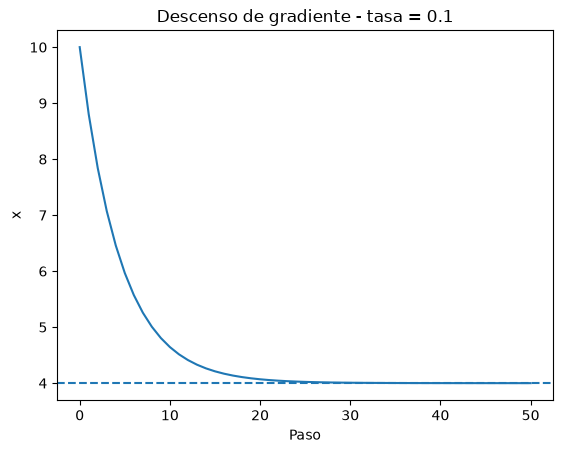

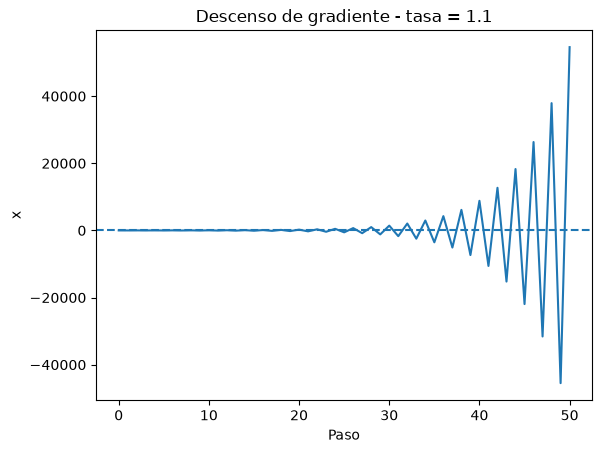

In [21]:
import matplotlib.pyplot as plt

for tasa in tasas:
    plt.figure()
    plt.plot(trayectorias[tasa])
    plt.axhline(4, linestyle="--")
    plt.title(f"Descenso de gradiente - tasa = {tasa}")
    plt.xlabel("Paso")
    plt.ylabel("x")
    plt.show()

In [22]:
for tasa in tasas:
    x_final = trayectorias[tasa][-1]
    error = abs(x_final - 4)
    
    print("Tasa:", tasa)
    print("x final:", x_final)
    print("Error respecto a 4:", error)
    print()

Tasa: 0.01
x final: 6.1850180805227035
Error respecto a 4: 2.1850180805227035

Tasa: 0.1
x final: 4.000085634861563
Error respecto a 4: 8.563486156276667e-05

Tasa: 1.1
x final: 54606.6289000133
Error respecto a 4: 54602.6289000133



El mínimo verdadero de la función se encuentra en x = 4.

Con una tasa de aprendizaje de 0.01, el algoritmo avanza hacia el mínimo lentamente, porque el tamaño de cada actualización es pequeño.

Con una tasa de 0.1, el algoritmo avanza de forma más rápida hacia x = 4 y se aproxima al mínimo.

Con una tasa de 1.1, la actualización es demasiado grande. El algoritmo puede pasar de un lado al otro del mínimo y oscilar, por lo que no se comporta de la misma manera que con una tasa pequeña o intermedia.

Por lo tanto, la tasa de aprendizaje influye directamente en la velocidad y estabilidad del descenso de gradiente.